# Corner Detection: Harris and Shi-Tomasi

A **corner** is a point where the brightness changes strongly in two directions, such as the corner of a chessboard square or the edge of a truck's windscreen. Corners are easy to find again in another image, which makes them the starting point for matching, tracking and calibration.

This notebook does the following:
1. Explains the **Harris** corner measure, the classic corner detector.
2. Finds the corners of a chessboard, and checks them against OpenCV's chessboard finder.
3. Replaces the dilate-and-threshold step with **non-maximum suppression**, which gives one point per corner.
4. Computes **Shi-Tomasi** corners, which are often preferred for tracking.
5. Refines the corners to **sub-pixel** accuracy.
6. Applies both detectors to a truck, after handling its transparent background.
7. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, Harris and Shi-Tomasi corners, sub-pixel refinement and drawing
- `matplotlib`: displaying images
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. How the Harris measure works

Move a small window over the image and measure how much the brightness changes when the window moves in each direction. The change is described by the **structure tensor** $M$, built from the image gradients $I_x$ and $I_y$, summed over the window. The two eigenvalues $\lambda_1, \lambda_2$ of $M$ describe the change:

- Both eigenvalues small: the window is on a **flat** area, and the brightness barely changes.
- One eigenvalue large: the window is on an **edge**, and the brightness changes in one direction only.
- Both eigenvalues large: the window is on a **corner**, and the brightness changes in every direction.

Harris and Stephens (1988) avoid computing the eigenvalues, and use the response

$$R = \det M - k\,(\operatorname{trace} M)^2 = \lambda_1 \lambda_2 - k\,(\lambda_1 + \lambda_2)^2$$

A large positive $R$ marks a corner, a negative $R$ marks an edge, and a small $|R|$ marks a flat area. $k$ is a constant, usually between 0.04 and 0.06.

## 3. Configuration

- `CHESSBOARD_PATH`: a chessboard with 8 × 8 squares, which has 7 × 7 inner corners.
- `TRUCK_PATH`: a truck photo with a transparent background.
- `BLOCK_SIZE`, `SOBEL_KSIZE`, `K`: the Harris settings. `BLOCK_SIZE` is the size of the window that is summed. `SOBEL_KSIZE` is the size of the gradient kernel.
- `REL_THRESHOLD`: a corner must have at least this fraction of the strongest response. The value 0.01 is a common starting point, and other values are compared below.
- `NMS_WINDOW`: the size of the window used to keep one maximum per corner.
- `CHESSBOARD_SIZE`: the number of inner corners of the chessboard, used as the reference.
- `BACKGROUND`: the grey value used for the transparent background of the truck.
- All results are saved to `OUTPUT_DIR`.

In [2]:
CHESSBOARD_PATH = Path("chessboard.jpg")
TRUCK_PATH = Path("truckrr.png")
OUTPUT_DIR = Path("output")

BLOCK_SIZE = 5
SOBEL_KSIZE = 3
K = 0.04
REL_THRESHOLD = 0.01
NMS_WINDOW = 7
CHESSBOARD_SIZE = (7, 7)
BACKGROUND = 128

## 4. Load the images and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `load_truck` loads the PNG with its alpha channel and places it on a neutral grey background. Without this, OpenCV drops the alpha channel and the grey colour of the transparent area is treated as part of the photo.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `harris_points` keeps the local maxima of the Harris response that are above the threshold, one point per corner.
- `match_rate` measures how many reference points have a detected point within a few pixels.
- `draw_points` draws the points on a copy of the image.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path, flags: int = cv2.IMREAD_COLOR) -> np.ndarray:
    """Load an image with OpenCV and raise a clear error if it fails."""
    image = cv2.imread(str(path), flags)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def load_truck(path: Path) -> np.ndarray:
    """BGR image with the transparent background replaced by a neutral grey."""
    raw = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if raw is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    if raw.shape[2] == 3:
        return raw
    alpha = raw[:, :, 3:4].astype(np.float32) / 255.0
    background = np.full(raw[:, :, :3].shape, BACKGROUND, dtype=np.float32)
    return (raw[:, :, :3] * alpha + background * (1 - alpha)).astype(np.uint8)


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def harris_points(response: np.ndarray, rel_threshold: float) -> np.ndarray:
    """One (x, y) point per corner: local maxima of the response above the threshold."""
    local_max = cv2.dilate(response, np.ones((NMS_WINDOW, NMS_WINDOW), np.uint8))
    keep = (response == local_max) & (response > rel_threshold * response.max())
    ys, xs = np.nonzero(keep)
    return np.column_stack([xs, ys]).astype(np.float32)


def match_rate(detected: np.ndarray, reference: np.ndarray, tolerance: float = 4.0) -> float:
    """Share of reference points that have a detected point within the tolerance (in pixels)."""
    if len(detected) == 0:
        return 0.0
    dists = np.linalg.norm(reference[:, None, :] - detected[None, :, :], axis=2)
    return float((dists.min(axis=1) <= tolerance).mean())


def precision(detected: np.ndarray, reference: np.ndarray, tolerance: float = 4.0) -> float:
    """Share of detected points that lie within the tolerance of a reference point."""
    if len(detected) == 0:
        return 0.0
    dists = np.linalg.norm(detected[:, None, :] - reference[None, :, :], axis=2)
    return float((dists.min(axis=1) <= tolerance).mean())


def draw_points(img: np.ndarray, points: np.ndarray, colour=(0, 255, 0), radius: int = 5) -> np.ndarray:
    """Copy of the image with a filled circle at each point."""
    out = img.copy()
    for x, y in np.round(points.reshape(-1, 2)).astype(int):
        cv2.circle(out, (int(x), int(y)), radius, colour, thickness=-1)
    return out


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

## 5. Harris corners on the chessboard

The Harris response is computed for every pixel. The corners are the local maxima above `REL_THRESHOLD` times the strongest response.

OpenCV's chessboard finder gives the true positions of the 49 inner corners. They are used as a reference:
- the **match rate** is the share of reference corners that the detector finds within 4 pixels (recall);
- the **precision** is the share of detected points that lie within 4 pixels of a reference corner.

Points on the image border are extra. The board runs to the edge of the photo, and the gradient filter responds to the edge of the image, so those points are not inner corners.

Harris corners: 64; chessboard reference corners: 49
Match rate within 4 px: 100%; precision within 4 px: 77%


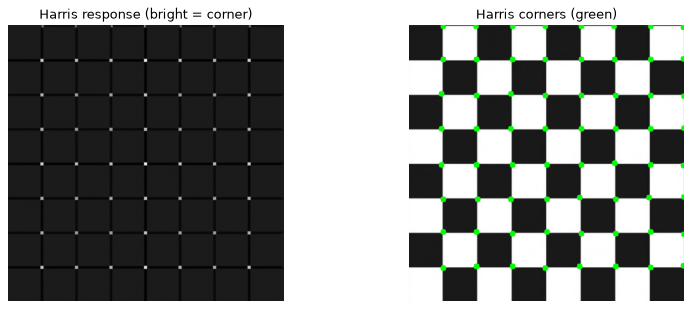

In [4]:
chess = load_image(CHESSBOARD_PATH)
chess_gray = cv2.cvtColor(chess, cv2.COLOR_BGR2GRAY)

response = cv2.cornerHarris(np.float32(chess_gray), BLOCK_SIZE, SOBEL_KSIZE, K)
harris = harris_points(response, REL_THRESHOLD)

found, reference = cv2.findChessboardCorners(chess_gray, CHESSBOARD_SIZE)
reference = reference.reshape(-1, 2) if found else np.empty((0, 2), np.float32)
print(f"Harris corners: {len(harris)}; chessboard reference corners: {len(reference)}")
print(f"Match rate within 4 px: {match_rate(harris, reference):.0%}; precision within 4 px: {precision(harris, reference):.0%}")

show_images({
    "Harris response (bright = corner)": cv2.normalize(response, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8),
    "Harris corners (green)": draw_points(chess, harris),
}, cols=2)

## 6. From the dilated map to one point per corner

A simple approach marks every pixel where the dilated response is above a threshold. A dilated corner is a blob of many pixels, so the marked area is larger than the corner itself. Non-maximum suppression keeps only the local maximum of each corner, as in section 5.

The next cell compares the thresholds 0.01 and 0.03 with the number of points that remain.

In [5]:
dilated = cv2.dilate(response, np.ones((8, 8), np.uint8))
for rel in (0.01, 0.03):
    marked = (dilated > rel * dilated.max()).sum()
    points = harris_points(response, rel)
    print(f"threshold {rel}: dilated map marks {marked} pixels; one point per corner: {len(points)} points, "
          f"match rate {match_rate(points, reference):.0%}")

threshold 0.01: dilated map marks 10274 pixels; one point per corner: 64 points, match rate 100%
threshold 0.03: dilated map marks 9770 pixels; one point per corner: 58 points, match rate 100%


## 7. Shi-Tomasi corners

Shi and Tomasi (1994) use the smaller eigenvalue $\min(\lambda_1, \lambda_2)$ as the corner score. A point is a good corner if both eigenvalues are large, so its window can be tracked in the next frame. `cv2.goodFeaturesToTrack` returns the strongest corners, with a minimum distance between them, so the corners are spread over the image.

Shi-Tomasi corners: 63; match rate within 4 px: 100%


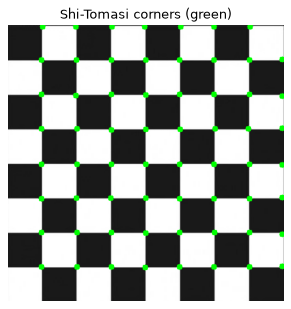

In [6]:
shi = cv2.goodFeaturesToTrack(chess_gray, maxCorners=200, qualityLevel=0.01, minDistance=10)
shi = shi.reshape(-1, 2)
print(f"Shi-Tomasi corners: {len(shi)}; match rate within 4 px: {match_rate(shi, reference):.0%}")

show_images({"Shi-Tomasi corners (green)": draw_points(chess, shi)})

## 8. Sub-pixel refinement

A corner is found on the pixel grid, so its position is off by up to half a pixel. `cv2.cornerSubPix` moves each corner to the point where the image gradients are perpendicular to the vectors from the corner, which gives a sub-pixel estimate. The mean shift is printed.

In [7]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.001)
refined = cv2.cornerSubPix(chess_gray, shi.reshape(-1, 1, 2).astype(np.float32), (5, 5), (-1, -1), criteria)
refined = refined.reshape(-1, 2)

shift = np.linalg.norm(refined - shi, axis=1)
print(f"Mean shift from sub-pixel refinement: {shift.mean():.2f} px; largest: {shift.max():.2f} px")
print(f"Match rate within 1 px, before: {match_rate(shi, reference, 1.0):.0%}, after: {match_rate(refined, reference, 1.0):.0%}")

Mean shift from sub-pixel refinement: 1.18 px; largest: 2.49 px
Match rate within 1 px, before: 53%, after: 100%


## 9. Corners on the truck

The truck PNG has a transparent background. The next cell compares the simple approach, which drops the alpha channel, with the neutral background from `load_truck`. Without the fix, the boundary between the truck and the transparent area produces corners that belong to the image file, not to the truck.

Truck: Harris 219 corners, Shi-Tomasi 200 corners
Without the background fix: Harris 300 corners


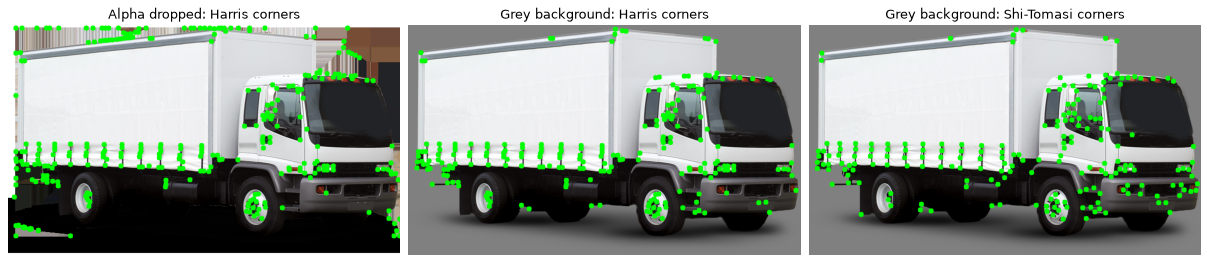

In [8]:
truck_raw = load_image(TRUCK_PATH)  # alpha channel dropped
truck = load_truck(TRUCK_PATH)
truck_gray = cv2.cvtColor(truck, cv2.COLOR_BGR2GRAY)

truck_response = cv2.cornerHarris(np.float32(truck_gray), BLOCK_SIZE, SOBEL_KSIZE, K)
truck_harris = harris_points(truck_response, REL_THRESHOLD)
truck_shi = cv2.goodFeaturesToTrack(truck_gray, maxCorners=200, qualityLevel=0.01, minDistance=10).reshape(-1, 2)
print(f"Truck: Harris {len(truck_harris)} corners, Shi-Tomasi {len(truck_shi)} corners")

raw_response = cv2.cornerHarris(np.float32(cv2.cvtColor(truck_raw, cv2.COLOR_BGR2GRAY)), BLOCK_SIZE, SOBEL_KSIZE, K)
raw_harris = harris_points(raw_response, REL_THRESHOLD)
print(f"Without the background fix: Harris {len(raw_harris)} corners")

show_images({
    "Alpha dropped: Harris corners": draw_points(truck_raw, raw_harris),
    "Grey background: Harris corners": draw_points(truck, truck_harris),
    "Grey background: Shi-Tomasi corners": draw_points(truck, truck_shi),
}, cols=3)

## 10. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [9]:
outputs = {
    f"{CHESSBOARD_PATH.stem}_harris": draw_points(chess, harris),
    f"{CHESSBOARD_PATH.stem}_shi_tomasi": draw_points(chess, refined),
    f"{TRUCK_PATH.stem}_harris_alpha_dropped": draw_points(truck_raw, raw_harris),
    f"{TRUCK_PATH.stem}_harris": draw_points(truck, truck_harris),
    f"{TRUCK_PATH.stem}_shi_tomasi": draw_points(truck, truck_shi),
}
for name, result in outputs.items():
    save_image(OUTPUT_DIR / f"{name}.jpg", result)

Saved output/chessboard_harris.jpg
Saved output/chessboard_shi_tomasi.jpg
Saved output/truckrr_harris_alpha_dropped.jpg
Saved output/truckrr_harris.jpg
Saved output/truckrr_shi_tomasi.jpg


## 11. Conclusion

- A **corner** is a point where the brightness changes in two directions. The **Harris** response $R$ tells corners, edges and flat areas apart from the two eigenvalues of the structure tensor.
- A threshold on the response turns it into points. The dilated map marks blobs. **Non-maximum suppression** keeps one point per corner, and its match rate on the chessboard is the measure to compare.
- **Shi-Tomasi** scores corners by the smaller eigenvalue. Its points are spread over the image with a minimum distance, which is why it is common in tracking.
- **Sub-pixel refinement** improves the positions of the corners. It matters when the corners are used for measurement, for example in camera calibration.
- Image **preprocessing** matters too. A transparent background must not be read as part of the image.

**Current standards beyond this notebook**
- **Keypoints with descriptors:** SIFT and ORB detect keypoints at several scales and describe each one, so that points can be matched between images. FAST is a fast corner test used inside ORB.
- **Learned keypoints:** networks such as SuperPoint learn the keypoints and their descriptors from data, and learned matchers such as LightGlue match them. These are the current methods for matching across large viewpoint changes. I have not benchmarked them here.